# 2 · Train your own decision head

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nipunbatra/system-one/blob/main/notebooks/02_train_a_decision_head.ipynb)

Companion to the lecture **System 1 models: deciding without writing**.

Notebook 1 read answers from the LLM's own next-token logits. Here we keep the LLM frozen and train a **small head** on the same vector, which is the idea behind decision models:

1. one forward pass gives a vector that summarises the input and the question,
2. a small head turns that vector into a probability per option,
3. the head is trained with a **proper scoring rule**, a loss that is smallest when the stated probability equals the true chance,
4. a held-out set calibrates the result.

Runs on a free Colab runtime (T4 recommended: about two minutes in total).

In [1]:
%pip install -q transformers datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, time, numpy as np, torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
name = "Qwen/Qwen2.5-0.5B-Instruct"          # 494 M parameters, a decoder-only transformer
tok = AutoTokenizer.from_pretrained(name)
tok.padding_side = "left"                     # so the last position is always the real last token
model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32).to(device).eval()
print(device, f"{sum(p.numel() for p in model.parameters())/1e6:.0f} M parameters,",
      model.config.num_hidden_layers, "layers, vocabulary", model.config.vocab_size)

W1120 17:28:40.998000 24420 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/290 [00:00<01:12,  4.01it/s]

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 971.00it/s]

mps 494 M parameters, 24 layers, vocabulary 151936


In [3]:
LETTERS = "ABCDEFGH"
letter_ids = [tok.encode(c, add_special_tokens=False)[0] for c in LETTERS]   # each letter is one token

def chat(user):
    """Wrap a user message in the model's chat format, ending where the answer starts."""
    return tok.apply_chat_template([{"role": "user", "content": user}],
                                   tokenize=False, add_generation_prompt=True)

def prompt(state, question, options):
    lines = [f"{LETTERS[i]}. {o}" for i, o in enumerate(options)]
    return chat(f"{state}\n\n{question}\n" + "\n".join(lines) + "\n\nAnswer with one letter.")

def ece(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf), np.asarray(correct, dtype=float)
    edges = np.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.any():
            gap = abs(correct[in_bin].mean() - conf[in_bin].mean())
            total += in_bin.mean() * gap          # weight = share of predictions in this bin
    return total

def bin_table(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf), np.asarray(correct, dtype=float)
    edges = np.linspace(0, 1, n_bins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        rows.append({"lo": round(float(lo), 2), "hi": round(float(hi), 2), "n": int(m.sum()),
                     "conf": round(float(conf[m].mean()), 4) if m.any() else None,
                     "acc": round(float(correct[m].mean()), 4) if m.any() else None})
    return rows

def reliability(conf, correct, title, ax):
    rows = [r for r in bin_table(conf, correct) if r["n"]]
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
    ax.plot([r["conf"] for r in rows], [r["acc"] for r in rows], "o-", color="#6d28d9")
    for r in rows:
        ax.annotate(str(r["n"]), (r["conf"], r["acc"]), textcoords="offset points", xytext=(6, -12), fontsize=8)
    ax.set(xlabel="confidence (the probability the model gave)", ylabel="accuracy (how often it was right)",
           title=f"{title}\nECE = {ece(conf, correct):.3f}", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.legend(loc="upper left")

TOPICS = ["World", "Sports", "Business", "Science and technology"]

def news_prompt(text):
    return prompt("News: " + text[:600], "Which topic is this news about?", TOPICS)

@torch.no_grad()
def run(texts, batch_size=16, want_hidden=False):
    """One forward pass per news item. Returns the 4 option logits (and the last hidden vector)."""
    all_logits, all_hidden = [], []
    for i in range(0, len(texts), batch_size):
        x = tok([news_prompt(t) for t in texts[i:i + batch_size]], return_tensors="pt", padding=True).to(device)
        out = model(**x, output_hidden_states=want_hidden)
        all_logits.append(out.logits[:, -1, letter_ids[:4]].float().cpu())
        if want_hidden:
            all_hidden.append(out.hidden_states[-1][:, -1].float().cpu())
    return (torch.cat(all_logits), torch.cat(all_hidden)) if want_hidden else torch.cat(all_logits)

## 1. A loss that rewards honesty

Suppose an answer is right 70% of the time. Which probability should the model state?

- **Accuracy** only checks whether the top answer was right. Saying 0.7 or 0.99 earns the same.
- The **Brier score** (p − y)² and the **log score** −log p are *proper scoring rules*: their expected value is best exactly at p = 0.7.

say 0.50: expected Brier = 0.250
say 0.70: expected Brier = 0.210
say 0.90: expected Brier = 0.250
say 0.99: expected Brier = 0.294


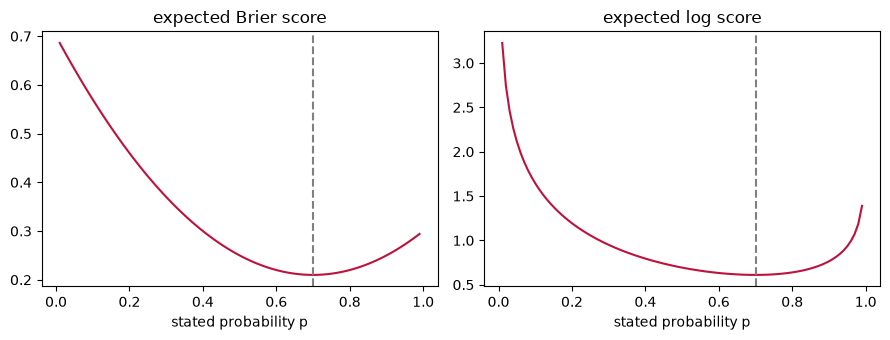

both curves are lowest at p = 0.7 and 0.7


In [4]:
true_chance = 0.7
p = np.linspace(0.01, 0.99, 99)
brier = true_chance * (1 - p) ** 2 + (1 - true_chance) * p ** 2          # expected (p - y)^2
logs  = -(true_chance * np.log(p) + (1 - true_chance) * np.log(1 - p))  # expected -log p(y)
for q in [0.5, 0.7, 0.9, 0.99]:
    print(f"say {q:.2f}: expected Brier = {true_chance * (1 - q) ** 2 + (1 - true_chance) * q ** 2:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(p, brier, color="#be123c"); ax[0].axvline(true_chance, ls="--", color="gray"); ax[0].set(title="expected Brier score", xlabel="stated probability p")
ax[1].plot(p, logs, color="#be123c");  ax[1].axvline(true_chance, ls="--", color="gray"); ax[1].set(title="expected log score", xlabel="stated probability p")
plt.tight_layout(); plt.show()
print("both curves are lowest at p =", p[brier.argmin()].round(2), "and", p[logs.argmin()].round(2))

## 2. One forward pass per item, keep the last vector

Same prompt as notebook 1. From each pass we keep two things: the four option-letter logits (the zero-shot answer) and the 896-number hidden vector at the last position.

In [5]:
train = load_dataset("fancyzhx/ag_news", split="train").shuffle(seed=0).select(range(2000))
ds = load_dataset("fancyzhx/ag_news", split="test").shuffle(seed=0)
val, test = ds.select(range(500)), ds.select(range(500, 1500))
t = time.perf_counter()
_, H_train = run(train["text"], want_hidden=True)
val_logits, H_val = run(val["text"], want_hidden=True)
test_logits, H_test = run(test["text"], want_hidden=True)
y_train, y_val, y_test = (torch.tensor(d["label"]) for d in (train, val, test))
print(f"{len(train) + len(val) + len(test)} forward passes in {time.perf_counter() - t:.0f} s; vectors:", tuple(H_train.shape))
mu, sd = H_train.mean(0), H_train.std(0) + 1e-6
H_train, H_val, H_test = ((h - mu) / sd for h in (H_train, H_val, H_test))

3500 forward passes in 80 s; vectors: (2000, 896)


In [6]:
def report(logits, y, label):
    probs = logits.softmax(-1); conf, pred = probs.max(-1); correct = (pred == y).float()
    brier = ((probs - torch.nn.functional.one_hot(y, 4)) ** 2).sum(-1).mean().item()
    out = {"accuracy": round(correct.mean().item(), 4), "mean_conf": round(conf.mean().item(), 4),
           "ece": round(ece(conf, correct), 4), "brier": round(brier, 4), "bins": bin_table(conf, correct)}
    print(f"{label:<34} accuracy {out['accuracy']:.3f}   mean confidence {out['mean_conf']:.3f}   ECE {out['ece']:.3f}   Brier {out['brier']:.3f}")
    return out

zero_shot = report(test_logits, y_test, "LLM letters, no training")

LLM letters, no training           accuracy 0.794   mean confidence 0.975   ECE 0.181   Brier 0.379


## 3. The head: one linear layer, trained with the log score

896 numbers in, 4 scores out. The LLM is not touched. Cross-entropy is the log score, a proper scoring rule.

In [7]:
def train_head(loss_name, steps=300):
    torch.manual_seed(0)
    head = torch.nn.Linear(H_train.shape[1], 4)
    opt = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=0.1)
    curve = []
    for step in range(steps):
        logits = head(H_train)
        if loss_name == "log":                                     # -log p(correct option)
            loss = torch.nn.functional.cross_entropy(logits, y_train)
        else:                                                      # Brier: squared distance to the one-hot answer
            loss = ((logits.softmax(-1) - torch.nn.functional.one_hot(y_train, 4)) ** 2).sum(-1).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        curve.append(round(loss.item(), 4))
    return head, curve

head, curve = train_head("log")
print("parameters in the head:", sum(p.numel() for p in head.parameters()), "| loss", curve[0], "->", curve[-1])
with torch.no_grad():
    head_test, head_val = head(H_test), head(H_val)
head_log = report(head_test, y_test, "trained head (log score)")

parameters in the head: 3588 | loss 1.6882 -> 0.1609
trained head (log score)           accuracy 0.884   mean confidence 0.908   ECE 0.037   Brier 0.185


In [8]:
head_b, curve_b = train_head("brier")
with torch.no_grad():
    head_brier = report(head_b(H_test), y_test, "trained head (Brier score)")

trained head (Brier score)         accuracy 0.885   mean confidence 0.908   ECE 0.039   Brier 0.183


## 4. Calibrate on held-out rows

The head has seen the training rows, so its confidence there is optimistic. We fit one temperature on the 500 held-out rows, as in notebook 1.

temperatures: head 1.10, LLM letters 3.30
LLM letters + temperature          accuracy 0.794   mean confidence 0.801   ECE 0.032   Brier 0.315
trained head + temperature         accuracy 0.884   mean confidence 0.895   ECE 0.019   Brier 0.184


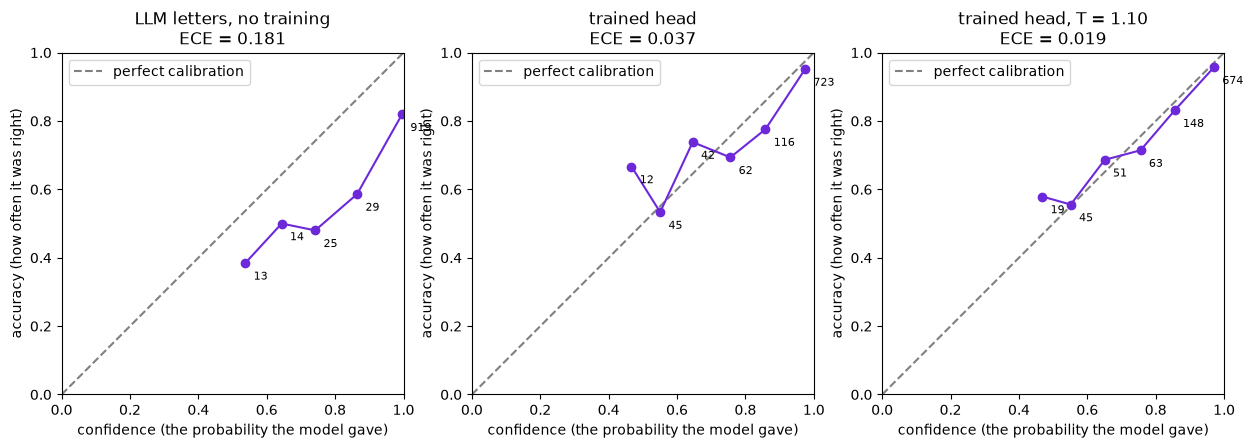

In [9]:
def fit_T(logits, y):
    Ts = np.linspace(0.5, 10, 191)
    return float(Ts[int(np.argmin([torch.nn.functional.cross_entropy(logits / T, y).item() for T in Ts]))])

T_head, T_zero = fit_T(head_val, y_val), fit_T(val_logits, y_val)
print(f"temperatures: head {T_head:.2f}, LLM letters {T_zero:.2f}")
zero_shot_T = report(test_logits / T_zero, y_test, "LLM letters + temperature")
head_log_T  = report(head_test / T_head, y_test, "trained head + temperature")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, lg, title in [(axes[0], test_logits, "LLM letters, no training"), (axes[1], head_test, "trained head"),
                      (axes[2], head_test / T_head, f"trained head, T = {T_head:.2f}")]:
    pr = lg.softmax(-1); c, pd_ = pr.max(-1); reliability(c, (pd_ == y_test).float(), title, ax)
plt.show()

## 5. Use it

One forward pass through the LLM, one matrix multiply in the head, four probabilities out.

In [10]:
@torch.no_grad()
def predict(text):
    _, h = run([text], want_hidden=True)
    probs = (head((h - mu) / sd) / T_head).softmax(-1)[0]
    return {t: round(v.item(), 3) for t, v in zip(TOPICS, probs)}

examples = ["Sensex closes 400 points higher as IT stocks rally after strong quarterly results.",
            "ISRO launches a new satellite to study how the monsoon forms over the Indian Ocean.",
            "The team chased 280 in the final over to level the one-day series."]
demo = []
for e in examples:
    out = predict(e); demo.append({"text": e, "probs": out}); print(out, "<-", e)

{'World': 0.004, 'Sports': 0.006, 'Business': 0.927, 'Science and technology': 0.062} <- Sensex closes 400 points higher as IT stocks rally after strong quarterly results.
{'World': 0.122, 'Sports': 0.016, 'Business': 0.023, 'Science and technology': 0.839} <- ISRO launches a new satellite to study how the monsoon forms over the Indian Ocean.
{'World': 0.022, 'Sports': 0.97, 'Business': 0.007, 'Science and technology': 0.002} <- The team chased 280 in the final over to level the one-day series.


In [11]:
results = {"n_train": len(train), "n_val": len(val), "n_test": len(test), "hidden": int(H_train.shape[1]),
           "head_params": sum(p.numel() for p in head.parameters()),
           "zero_shot": zero_shot, "zero_shot_T": zero_shot_T, "head_log": head_log, "head_brier": head_brier,
           "head_log_T": head_log_T, "T_head": round(T_head, 2), "T_zero": round(T_zero, 2),
           "curve": curve[::10], "demo": demo,
           "head_conf_T": [round(v, 3) for v in (head_test / T_head).softmax(-1).max(-1).values.tolist()],
           "head_correct": [int(v) for v in ((head_test.argmax(-1)) == y_test).tolist()],
           "expected_brier": {str(q): round(0.7 * (1 - q) ** 2 + 0.3 * q ** 2, 4) for q in [0.5, 0.7, 0.9, 1.0]}}
json.dump(results, open("results_2.json", "w"))
print("saved results_2.json")

saved results_2.json


## Things to try

- Train on 200 rows instead of 2,000. What happens to accuracy and to ECE before the temperature?
- Train for 3,000 steps. The training loss keeps falling. Does the test ECE?
- Unfreeze the LLM with LoRA instead of training only a head. That is notebook 3.